In [1]:
# Dataset cell and donor summary
#
# This notebook compares the .obs tables from the SlideTags and NucSeq datasets.
# It uses donor_id to count samples and donor overlap, and uses dataset membership
# to define spatial status: all SlideTags cells are spatial and all NucSeq cells
# are non-spatial.

In [2]:
import pandas as pd
import scanpy as sc

In [31]:
n = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/Striatum/Striatum_combined_QC_mmc_ct-cured_zoned.h5ad", backed="r")
n_dfc = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/DFC/DFC_combined_QC_mmc_ct-cured.h5ad", backed="r")
n_sn = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/SN/SN_combined_QC_mmc_ct-cured.h5ad", backed="r")
a = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/all_lib_adata_zoned_ct-cured_aligned.h5ad", backed="r")

In [4]:
DONOR = "donor_id"
CONDITION = "condition"

# Dataset membership is the source of truth for spatial status.
DATASET_SPATIAL = {
    "SlideTags": True,
    "NucSeq": False,
}

In [32]:
# Copy only .obs into ordinary pandas DataFrames. This keeps the analysis small
# even when the AnnData objects are opened in backed mode.
obs_by_dataset = {
    "SlideTags": a.obs.copy(),
    "NucSeq": pd.concat(
        [n.obs.copy(), n_dfc.obs.copy(), n_sn.obs.copy()],
        axis=0,
        ignore_index=True,
    ),
}

for dataset_name, obs in obs_by_dataset.items():
    missing_columns = [column for column in (DONOR, CONDITION) if column not in obs.columns]
    if missing_columns:
        raise KeyError(
            f"{dataset_name} is missing required .obs column(s): {missing_columns}. "
            f"Available columns include: {list(obs.columns)}"
        )


def classify_condition(value):
    """Normalize common condition labels to healthy, diseased, or other."""
    label = str(value).strip().lower()
    if any(word in label for word in ("healthy", "control", "ctrl", "normal")):
        return "healthy"
    if any(word in label for word in ("diseased", "disease", "case", "patient", "xdp")):
        return "diseased"
    return "other"


# Spatial status is defined by the dataset: every SlideTags cell is spatial,
# while every NucSeq cell is non-spatial. The resulting column is named
# has_spatial so it can be used directly in the summaries below.
frames = []
for dataset_name, obs in obs_by_dataset.items():
    frame = obs[[DONOR, CONDITION]].copy()
    frame["dataset"] = dataset_name
    frame["has_spatial"] = DATASET_SPATIAL[dataset_name]
    frame["condition_group"] = frame[CONDITION].map(classify_condition)
    frames.append(frame)

# Cells without condition metadata are excluded from all downstream results.
cells = pd.concat(frames, axis=0, ignore_index=True)
cells = cells.loc[cells[CONDITION].notna()].copy()

# Add one explicit placeholder cell so donor SCF-21-032 is represented in
# SlideTags while the real cell-level data are unavailable. This row is synthetic.
SYNTHETIC_CELLS = pd.DataFrame(
    [{
        DONOR: "SCF-21-032",
        CONDITION: "XDP",
        "dataset": "SlideTags",
        "has_spatial": True,
        "condition_group": "diseased",
    }]
)
cells = pd.concat([cells, SYNTHETIC_CELLS], ignore_index=True)
print("WARNING: one synthetic diseased SlideTags cell was added for donor SCF-21-032.")

cells[DONOR] = cells[DONOR].astype("string")

# Display normalized condition groups, so labels such as XDP and diseased
# are combined when they represent the same biological condition.
condition_labels = (
    cells.groupby(["dataset", "condition_group"], dropna=False)
    .size()
    .rename("cells")
    .reset_index()
    .sort_values(["dataset", "condition_group"])
)
print("Cells by dataset and normalized condition group:")
display(condition_labels)

# 1. Total cells, spatial cells, and non-spatial cells.
cell_totals = len(cells)
spatial_cell_total = int(cells["has_spatial"].sum())
non_spatial_cell_total = int((~cells["has_spatial"]).sum())
print(f"Total cells across both datasets: {cell_totals:,}")
print(f"Cells with spatial location: {spatial_cell_total:,}")
print(f"Cells without spatial location: {non_spatial_cell_total:,}")

# 2. Cell counts split by condition, and then by condition and dataset.
condition_cell_summary = (
    cells.groupby("condition_group", dropna=False)
    .size()
    .reindex(["healthy", "diseased"], fill_value=0)
    .rename("cells")
    .to_frame()
)
condition_dataset_cell_summary = (
    cells.groupby(["dataset", "condition_group"], dropna=False)
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["healthy", "diseased"], fill_value=0)
)
print("Cells split by condition:")
display(condition_cell_summary)
print("Cells split by dataset and condition:")
display(condition_dataset_cell_summary)

# 3. Spatial/non-spatial cells split by condition.
spatial_cell_summary = (
    cells.groupby(["has_spatial", "condition_group"], dropna=False)
    .size()
    .unstack(fill_value=0)
    .reindex(index=[True, False], columns=["healthy", "diseased"], fill_value=0)
)
print("Cells split by spatial status and condition:")
display(spatial_cell_summary)

# 4. Use this single filtered donor table for every donor summary.
donor_cells = cells.dropna(subset=[DONOR]).drop_duplicates(
    ["dataset", DONOR, "condition_group", "has_spatial"]
)
donors_by_dataset = {
    dataset_name: set(donor_cells.loc[donor_cells["dataset"] == dataset_name, DONOR])
    for dataset_name in obs_by_dataset
}
all_donors = donors_by_dataset["SlideTags"] | donors_by_dataset["NucSeq"]
overlapping_donors = donors_by_dataset["SlideTags"] & donors_by_dataset["NucSeq"]
donor_summary = pd.DataFrame(
    {
        "measure": [
            "SlideTags donors",
            "NucSeq donors",
            "unique donors across both datasets",
            "donors present in both datasets",
        ],
        "donors": [
            len(donors_by_dataset["SlideTags"]),
            len(donors_by_dataset["NucSeq"]),
            len(all_donors),
            len(overlapping_donors),
        ],
    }
).set_index("measure")
print("Donor counts:")
display(donor_summary)

donor_condition_summary = (
    donor_cells.groupby(["dataset", "has_spatial", "condition_group"])[DONOR]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=["healthy", "diseased"], fill_value=0)
)
print("Donors split by dataset, spatial status, and condition:")
display(donor_condition_summary)

spatial_donor_summary = (
    donor_cells[donor_cells["has_spatial"]]
    .groupby("condition_group")[DONOR]
    .nunique()
    .reindex(["healthy", "diseased"], fill_value=0)
    .rename("donors")
    .to_frame()
)
non_spatial_donor_summary = (
    donor_cells[~donor_cells["has_spatial"]]
    .groupby("condition_group")[DONOR]
    .nunique()
    .reindex(["healthy", "diseased"], fill_value=0)
    .rename("donors")
    .to_frame()
)
print("Spatial donors by condition (SlideTags):")
display(spatial_donor_summary)
print("Non-spatial donors by condition (NucSeq):")
display(non_spatial_donor_summary)

print("\nNamed outputs available for follow-up analysis:")
print("cells, cell_totals, spatial_cell_total, non_spatial_cell_total,")
print("condition_cell_summary, condition_dataset_cell_summary, spatial_cell_summary,")
print("donor_summary, overlapping_donors, donor_condition_summary,")
print("spatial_donor_summary, and non_spatial_donor_summary")

Cells by dataset and normalized condition group:


,dataset,condition_group,cells
0,NucSeq,diseased,309328
1,NucSeq,healthy,189381
2,SlideTags,diseased,527577
3,SlideTags,healthy,163760


Total cells across both datasets: 1,190,046
Cells with spatial location: 691,337
Cells without spatial location: 498,709
Cells split by condition:


,cells
condition_group,
healthy,353141
diseased,836905


Cells split by dataset and condition:


condition_group,healthy,diseased
dataset,,
NucSeq,189381,309328
SlideTags,163760,527577


... (7 outputs left out)

,donors
condition_group,
healthy,4
diseased,8


Non-spatial donors by condition (NucSeq):


,donors
condition_group,
healthy,17
diseased,30



Named outputs available for follow-up analysis:
cells, cell_totals, spatial_cell_total, non_spatial_cell_total,
condition_cell_summary, condition_dataset_cell_summary, spatial_cell_summary,
donor_summary, overlapping_donors, donor_condition_summary,
spatial_donor_summary, and non_spatial_donor_summary


In [ ]:
# Tissue-level counts. SlideTags is treated as Striatum because its cells are
# from the striatal spatial dataset; the three NucSeq tissues stay identifiable
# here even though they are combined as one NucSeq dataset elsewhere.
tissue_inputs = [
    ("SlideTags", "Striatum", a.obs.copy(), True),
    ("NucSeq", "Striatum", n.obs.copy(), False),
    ("NucSeq", "DFC", n_dfc.obs.copy(), False),
    ("NucSeq", "SN", n_sn.obs.copy(), False),
]

tissue_frames = []
for dataset_name, tissue_name, obs, has_spatial in tissue_inputs:
    tissue_frame = obs[[DONOR, CONDITION]].copy()
    tissue_frame["dataset"] = dataset_name
    tissue_frame["tissue"] = tissue_name
    tissue_frame["has_spatial"] = has_spatial
    tissue_frame["condition_group"] = tissue_frame[CONDITION].map(classify_condition)
    tissue_frames.append(tissue_frame.loc[tissue_frame[CONDITION].notna()])

tissue_cells = pd.concat(tissue_frames, axis=0, ignore_index=True)

# Keep the same synthetic SlideTags cell in the tissue-level Striatum count.
tissue_cells = pd.concat(
    [
        tissue_cells,
        pd.DataFrame(
            [{
                DONOR: "SCF-21-032",
                CONDITION: "XDP",
                "dataset": "SlideTags",
                "tissue": "Striatum",
                "has_spatial": True,
                "condition_group": "diseased",
            }]
        ),
    ],
    ignore_index=True,
)

print("Cells per tissue:")
display(
    tissue_cells.groupby(["dataset", "tissue"])
    .size()
    .rename("cells")
    .to_frame()
)

print("Cells per tissue and condition:")
display(
    tissue_cells.groupby(["dataset", "tissue", "condition_group"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["healthy", "diseased"], fill_value=0)
)

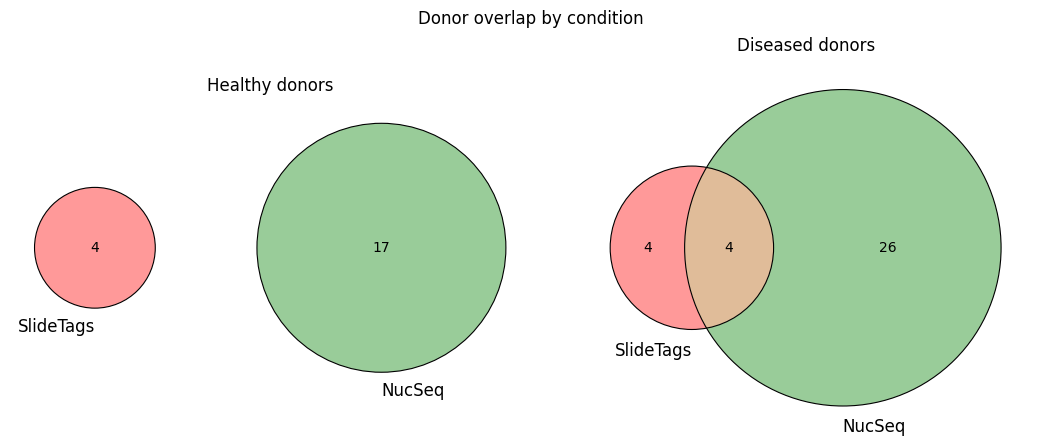

Venn-plot donor sets:
healthy: SlideTags=4, NucSeq=17, overlap=0
diseased: SlideTags=8, NucSeq=30, overlap=4


In [33]:
# Venn plots show donor overlap separately for healthy and diseased samples.
# A donor is included in a condition only when that condition is present in
# at least one of its cells in the corresponding dataset.
import matplotlib.pyplot as plt
from matplotlib_venn import venn2, venn2_circles

condition_donors = {}
for condition in ("healthy", "diseased"):
    condition_donors[condition] = {
        dataset_name: set(
            donor_cells.loc[
                (donor_cells["dataset"] == dataset_name)
                & (donor_cells["condition_group"] == condition),
                DONOR,
            ].dropna().unique()
        )
        for dataset_name in ("SlideTags", "NucSeq")
    }

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, condition in zip(axes, ("healthy", "diseased")):
    donor_sets = condition_donors[condition]
    venn2(
        [donor_sets["SlideTags"], donor_sets["NucSeq"]],
        set_labels=("SlideTags", "NucSeq"),
        ax=axis,
    )
    venn2_circles([donor_sets["SlideTags"], donor_sets["NucSeq"]], ax=axis, linewidth=0.8)
    axis.set_title(f"{condition.title()} donors")

fig.suptitle("Donor overlap by condition")
fig.tight_layout()
plt.show()

print("Venn-plot donor sets:")
for condition, donor_sets in condition_donors.items():
    print(
        f"{condition}: SlideTags={len(donor_sets['SlideTags'])}, "
        f"NucSeq={len(donor_sets['NucSeq'])}, "
        f"overlap={len(donor_sets['SlideTags'] & donor_sets['NucSeq'])}"
    )

In [10]:
a = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/all_lib_adata_zoned_ct-cured_aligned.h5ad")#, backed="r")

In [11]:
a


AnnData object with n_obs × n_vars = 691336 × 37559
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'original_barcode', 'donor_number', 'donor_id', 'condition', 'sex', 'age_at_onset', 'age_at_death', 'bcl', 'library', 'Sorted', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4_probability

In [12]:
a.obs = a.obs[[
    'x', 'y', 
    'pct_intronic', 
    'sample', 
    'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 
    'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 
    'library_id', 'original_barcode', 'donor_number', 'donor_id', 'condition', 'sex', 'age_at_onset', 'age_at_death', 
    'bcl', 'library', 'Sorted', 
    'mapping_coupling_for_zoning', 'zone', 'zone_probability', 
    'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4_probability', 
]].copy()

In [14]:
a.var = a.var[["gene_symbol"]].copy()

In [ ]:
#drop all obsm, apert from spatial
a.obsm = {}
if 'spatial' in a.uns:
    if 'aperture' in a.uns['spatial']:
        del a.uns['spatial']['aperture']
    if 'obsm' in a.uns['spatial']:
        del a.uns['spatial']['obsm']    

In [16]:
a.X = a.layers["counts"].copy()
a.layers = {}

In [17]:
a

AnnData object with n_obs × n_vars = 691336 × 37559
    obs: 'x', 'y', 'pct_intronic', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'original_barcode', 'donor_number', 'donor_id', 'condition', 'sex', 'age_at_onset', 'age_at_death', 'bcl', 'library', 'Sorted', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4_probability'
    var: 'gene_symbol'

In [20]:
import pandas as pd

for col in a.obs.columns:
    if a.obs[col].isna().any():
        print(f"{col}: {a.obs[col].isna().sum()} NaN values")

x: 104473 NaN values
y: 104473 NaN values
mapping_coupling_for_zoning: 565460 NaN values
zone: 570912 NaN values
zone_probability: 565460 NaN values
mapping_coupling_for_zoning_4_zones: 586753 NaN values
zone_4: 586753 NaN values
zone_4_probability: 586753 NaN values


In [4]:
obs = a.obs.copy()


In [8]:
obs.library_id

251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGATAACAG-1    251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGCATGGAG-1    251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGGCGGAGT-1    251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGGTCTATG-1    251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGGTTGTAT-1    251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1
                                                                                  ...                  
260721_SL-EXB_0892_B23Y3GKLT4---SI-TT-H3---GTTGTCTTCGTTCTAC-1    260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H3
260721_SL-EXB_0892_B23Y3GKLT4---SI-TT-H3---GTTGTGCAGATCACAT-1    260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H3
260721_SL-EXB_0892_B23Y3GKLT4---SI-TT-H3---GTTGTGGGTACCATCC-1    260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H3
260721_SL-EXB_0892_B23Y3GKLT4---SI-TT-H3---GTTGTGGGTCATACTT-1   

In [9]:
obs.library_id.unique()

['251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1', '251027_SL-EXD_0706_A233KGFLT4_SI-TT-H2', '251027_SL-EXD_0706_A233KGFLT4_SI-TT-H3', '260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B10', '260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B11', ..., '260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-G6', '260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-G7', '260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H1', '260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H2', '260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H3']
Length: 47
Categories (47, object): ['240911_SL-EXD_0362_A22FLV2LT4_SI-TT-E1', '240911_SL-EXD_0362_A22FLV2LT4_SI-TT-E2', '240911_SL-EXD_0362_A22FLV2LT4_SI-TT-E3', '240911_SL-EXD_0362_A22FLV2LT4_SI-TT-E4', ..., '260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-G7', '260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H1', '260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H2', '260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H3']

In [ ]:
sc.pl.embedding(a[a.obs['sample']=='sample_02'], basis)